# Analise Exploratoria e Definicao do Baseline Operacional — Dados Forzy

**Sprint 3** | Deteccao de Anomalias em Sensores de Vibracao Industrial

Este notebook analisa o historico real de sensores de vibracao e temperatura
fornecido pela Forzy (`forzy_history.csv`), com dois objetivos:

1. Compreender o comportamento historico do ativo monitorado (analise exploratoria)
2. Definir o **baseline operacional** — o comportamento esperado do equipamento —
   que servira de referencia para o modelo de deteccao de anomalias no notebook seguinte.

**Sumario:**
1. Carregamento e Parsing dos Dados Brutos
2. Inspecao Geral e Qualidade dos Dados
3. Identificacao dos Estados Operacionais (Repouso x Operacao)
4. Distribuicao dos Sensores por Estado
5. Evolucao Temporal e Ciclos de Operacao
6. Correlacao entre Sensores e Pontos de Medicao
7. Deteccao de Outliers
8. Definicao do Baseline Operacional


## 1. Carregamento e Parsing dos Dados Brutos

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

# O arquivo bruto tem 3 linhas de cabecalho tecnico do IO-Link Master
# (nome do canal, descricao do parametro, tipo de dado) que sao descartadas.
df = pd.read_csv('forzy_history.csv', sep=';', skiprows=3, header=None, encoding='utf-8')
df.columns = [
    'timestamp', 'port1_raw', 'port2_raw',
    'p1_velocidade', 'p1_aceleracao', 'p1_temperatura',
    'p2_velocidade', 'p2_aceleracao', 'p2_temperatura'
]

# As colunas de array de bytes brutos sao redundantes com os canais ja decodificados
df = df.drop(columns=['port1_raw', 'port2_raw'])
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

SENSOR_COLS = ['p1_velocidade', 'p1_aceleracao', 'p1_temperatura',
               'p2_velocidade', 'p2_aceleracao', 'p2_temperatura']

print(f"Shape: {df.shape}")
print(f"Periodo: {df['timestamp'].min()} ate {df['timestamp'].max()}")
print(f"Duracao total: {df['timestamp'].max() - df['timestamp'].min()}")
df.head()


Shape: (7183, 7)
Periodo: 2026-05-19 11:46:10.921000 ate 2026-05-19 15:43:14.082000
Duracao total: 0 days 03:57:03.161000


,timestamp,p1_velocidade,p1_aceleracao,p1_temperatura,p2_velocidade,p2_aceleracao,p2_temperatura
0,2026-05-19 11:46:10.921,0.04,0.0,27,0.04,0.0,34
1,2026-05-19 11:46:11.290,0.04,0.0,27,0.04,0.0,34
2,2026-05-19 11:46:14.920,0.04,0.0,27,0.04,0.0,34
3,2026-05-19 11:46:15.296,0.04,0.0,27,0.03,0.0,34
4,2026-05-19 11:46:21.919,0.04,0.0,27,0.03,0.0,34


## 2. Inspecao Geral e Qualidade dos Dados

In [2]:
print("=== Valores nulos ===")
print(df[SENSOR_COLS].isnull().sum())

print("\n=== Estatisticas descritivas ===")
display(df[SENSOR_COLS].describe().round(3))

# Amostragem irregular: calcular intervalo entre leituras consecutivas
df['dt_seg'] = df['timestamp'].diff().dt.total_seconds()
print("\n=== Intervalo entre leituras consecutivas (segundos) ===")
print(df['dt_seg'].describe())
print()
print("A amostragem e IRREGULAR (padrao 'report-on-change' do IO-Link):")
print("o sensor reporta com mais frequencia quando o valor varia (operacao)")
print("e com menos frequencia quando o valor esta estavel (repouso).")


=== Valores nulos ===
p1_velocidade     0
p1_aceleracao     0
p1_temperatura    0
p2_velocidade     0
p2_aceleracao     0
p2_temperatura    0
dtype: int64

=== Estatisticas descritivas ===


,p1_velocidade,p1_aceleracao,p1_temperatura,p2_velocidade,p2_aceleracao,p2_temperatura
count,7183.000,7183.000,7183.000,7183.000,7183.000,7183.000
mean,2.500,0.187,31.936,2.619,0.190,37.396
std,2.895,0.223,4.594,2.995,0.226,3.614
min,0.030,0.000,27.000,0.030,0.000,33.000
25%,0.040,0.000,28.000,0.040,0.000,35.000
50%,0.640,0.040,31.000,0.740,0.040,36.000
75%,6.380,0.480,34.000,6.430,0.470,39.000
max,7.460,0.580,46.000,7.730,0.600,47.000



=== Intervalo entre leituras consecutivas (segundos) ===
count    7182.000000
mean        1.980390
std         7.351316
min         0.000000
25%         0.316000
50%         0.594500
75%         0.912000
max       228.381000
Name: dt_seg, dtype: float64

A amostragem e IRREGULAR (padrao 'report-on-change' do IO-Link):
o sensor reporta com mais frequencia quando o valor varia (operacao)
e com menos frequencia quando o valor esta estavel (repouso).


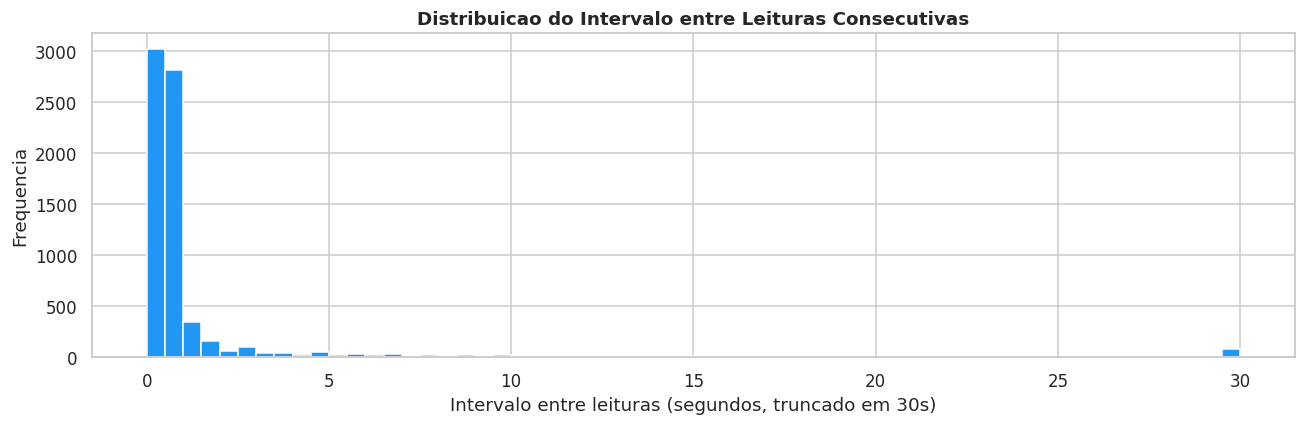

Mediana do intervalo: 0.59s
Intervalos > 60s (repouso prolongado): 21 casos


In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(df['dt_seg'].clip(upper=30), bins=60, color='#2196F3', edgecolor='white')
ax.set_xlabel('Intervalo entre leituras (segundos, truncado em 30s)')
ax.set_ylabel('Frequencia')
ax.set_title('Distribuicao do Intervalo entre Leituras Consecutivas', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_intervalo_leituras.png', bbox_inches='tight')
plt.show()

print(f"Mediana do intervalo: {df['dt_seg'].median():.2f}s")
print(f"Intervalos > 60s (repouso prolongado): {(df['dt_seg'] > 60).sum()} casos")


## 3. Identificacao dos Estados Operacionais

Antes de qualquer analise estatistica, e essencial identificar que o equipamento
opera em **dois regimes distintos**: repouso (idle) e operacao (running). Tratar
os dados como um unico regime levaria a um baseline estatistico incorreto — a
media geral de vibracao misturaria valores de repouso (~0,04 mm/s) com valores
de operacao (~5-7 mm/s), produzindo um baseline que nao representa nenhum dos
dois estados reais.


In [4]:
# Limiar de operacao: 0.5 mm/s esta bem acima do ruido de fundo em repouso (~0.04-0.10)
# e bem abaixo dos valores minimos observados durante operacao (~0.19-0.25)
THRESH_RUNNING = 0.5

df['running'] = (df['p1_velocidade'] > THRESH_RUNNING) | (df['p2_velocidade'] > THRESH_RUNNING)
df['cycle_id'] = (df['running'] != df['running'].shift()).cumsum()

print(f"Leituras em REPOUSO : {(~df['running']).sum():5d} ({(~df['running']).mean()*100:.1f}%)")
print(f"Leituras em OPERACAO: {df['running'].sum():5d} ({df['running'].mean()*100:.1f}%)")

# Tabela de ciclos de operacao
cycles = df[df['running']].groupby('cycle_id').agg(
    inicio=('timestamp', 'min'), fim=('timestamp', 'max'),
    n_leituras=('timestamp', 'count'),
    vel_max_p1=('p1_velocidade', 'max'), vel_max_p2=('p2_velocidade', 'max'),
    temp_max_p1=('p1_temperatura', 'max'), temp_max_p2=('p2_temperatura', 'max'),
).reset_index(drop=True)
cycles.index = range(1, len(cycles) + 1)
cycles.index.name = 'ciclo'
cycles['duracao_min'] = (cycles['fim'] - cycles['inicio']).dt.total_seconds() / 60

print(f"\nTotal de ciclos operacionais identificados: {len(cycles)}")
display(cycles[['inicio', 'fim', 'duracao_min', 'n_leituras',
                 'vel_max_p1', 'vel_max_p2', 'temp_max_p1', 'temp_max_p2']].round(2))


Leituras em REPOUSO :  3392 (47.2%)
Leituras em OPERACAO:  3791 (52.8%)

Total de ciclos operacionais identificados: 6


,inicio,fim,duracao_min,n_leituras,vel_max_p1,vel_max_p2,temp_max_p1,temp_max_p2
ciclo,,,,,,,,
1,2026-05-19 11:48:42.494,2026-05-19 11:50:43.918,2.02,243,6.43,6.15,27,34
2,2026-05-19 11:50:56.771,2026-05-19 11:53:04.920,2.14,257,4.54,4.88,27,34
3,2026-05-19 12:16:47.365,2026-05-19 12:18:36.916,1.83,219,4.65,5.56,28,35
4,2026-05-19 12:21:16.478,2026-05-19 12:25:42.915,4.44,531,5.91,6.37,28,34
5,2026-05-19 13:12:22.531,2026-05-19 13:16:41.913,4.32,513,7.46,7.73,30,36
6,2026-05-19 13:44:28.388,2026-05-19 14:01:53.919,17.43,2028,7.05,7.52,39,43


**Interpretacao:** foram identificados 6 ciclos de operacao no periodo monitorado.
Os cinco primeiros duram entre 2 e 4,4 minutos, com velocidade de pico entre
4,5 e 7,7 mm/s e temperatura maxima entre 27-30°C (Porta 1) e 34-36°C (Porta 2).

O **sexto ciclo se destaca nitidamente**: dura 17,4 minutos — quase 4x mais que
o segundo ciclo mais longo — e atinge temperatura maxima de 39°C (Porta 1) e
43°C (Porta 2) durante a operacao, com pico de resfriamento posterior ainda
mais alto. Esse ciclo e o principal candidato a comportamento anomalo e sera
investigado em profundidade no notebook de treinamento.


## 4. Distribuicao dos Sensores por Estado Operacional

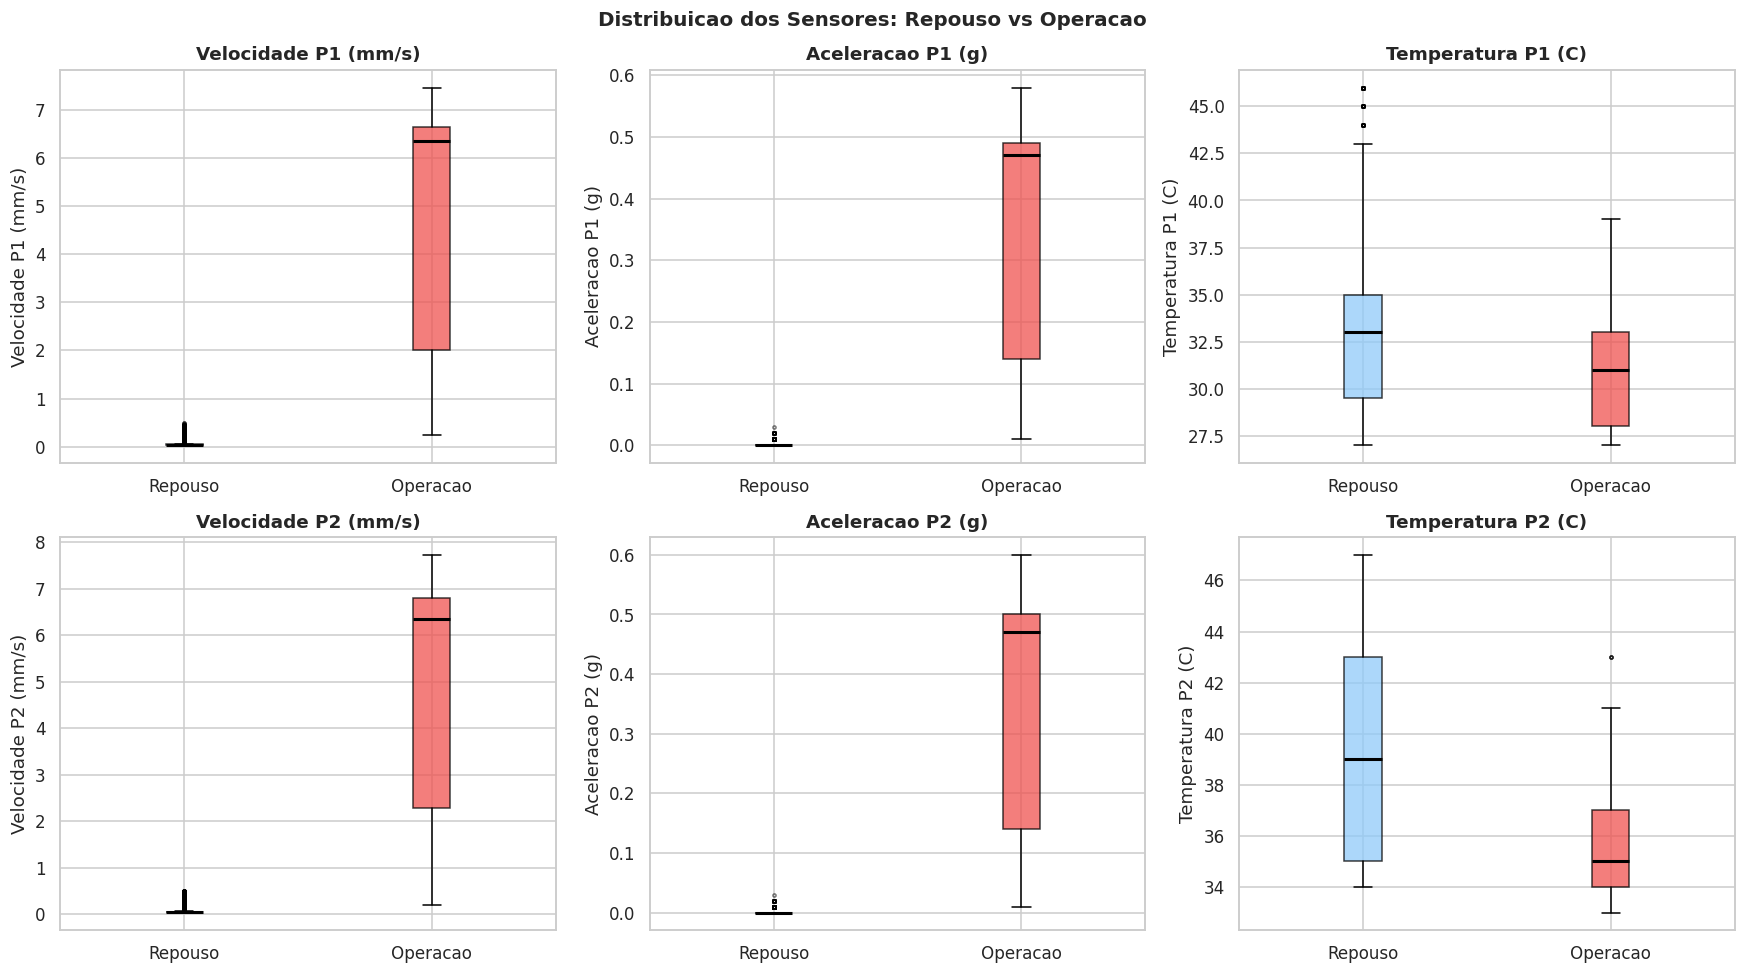

Estatisticas por estado:

--- REPOUSO ---
      p1_velocidade  p1_aceleracao  p1_temperatura  p2_velocidade  \
mean          0.073          0.001          33.296          0.077   
std           0.085          0.004           5.309          0.098   
min           0.030          0.000          27.000          0.030   
max           0.500          0.030          46.000          0.500   

      p2_aceleracao  p2_temperatura  
mean          0.001          39.030  
std           0.005           4.186  
min           0.000          34.000  
max           0.030          47.000  

--- OPERACAO ---
      p1_velocidade  p1_aceleracao  p1_temperatura  p2_velocidade  \
mean          4.672          0.352          30.719          4.893   
std           2.426          0.189           3.411          2.455   
min           0.250          0.010          27.000          0.190   
max           7.460          0.580          39.000          7.730   

      p2_aceleracao  p2_temperatura  
mean          0.358 

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
labels_sensores = ['Velocidade P1 (mm/s)', 'Aceleracao P1 (g)', 'Temperatura P1 (C)',
                    'Velocidade P2 (mm/s)', 'Aceleracao P2 (g)', 'Temperatura P2 (C)']

for ax, col, lbl in zip(axes.flat, SENSOR_COLS, labels_sensores):
    data_idle = df[~df['running']][col]
    data_run  = df[df['running']][col]
    bp = ax.boxplot([data_idle, data_run], patch_artist=True, showfliers=True,
                    medianprops=dict(color='black', linewidth=2),
                    flierprops=dict(marker='o', markersize=2, alpha=0.3))
    for patch, cor in zip(bp['boxes'], ['#90CAF9', '#EF5350']):
        patch.set_facecolor(cor); patch.set_alpha(0.75)
    ax.set_xticklabels(['Repouso', 'Operacao'])
    ax.set_title(lbl, fontweight='bold')
    ax.set_ylabel(lbl)

plt.suptitle('Distribuicao dos Sensores: Repouso vs Operacao', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_distribuicao_estados.png', bbox_inches='tight')
plt.show()

print("Estatisticas por estado:")
for estado, mask in [('REPOUSO', ~df['running']), ('OPERACAO', df['running'])]:
    print(f"\n--- {estado} ---")
    print(df[mask][SENSOR_COLS].describe().loc[['mean','std','min','max']].round(3))


**Interpretacao:**

- A separacao entre os dois estados e nitida em velocidade e aceleracao: o
  repouso concentra-se proximo de zero (ruido de fundo do sensor), enquanto a
  operacao apresenta grande dispersao (0,19 a 7,7 mm/s), refletindo as fases de
  ramp-up, regime e desaceleracao dentro de cada ciclo.

- A temperatura apresenta um padrao diferente: nao salta abruptamente com o
  estado, mas sim **acumula calor gradualmente** ao longo dos ciclos de operacao
  e dissipa lentamente durante o repouso — comportamento fisico esperado de
  inercia termica. Por isso, a temperatura de repouso tem uma cauda longa
  (chegando a 46-47°C), pois inclui os periodos de resfriamento apos os ciclos
  mais quentes.

- A Porta 2 e sistematicamente ~5-6°C mais quente que a Porta 1 em ambos os
  estados — um offset fisico constante (provavelmente o ponto de medicao mais
  proximo da fonte de calor do motor), nao uma anomalia.


## 5. Evolucao Temporal e Ciclos de Operacao

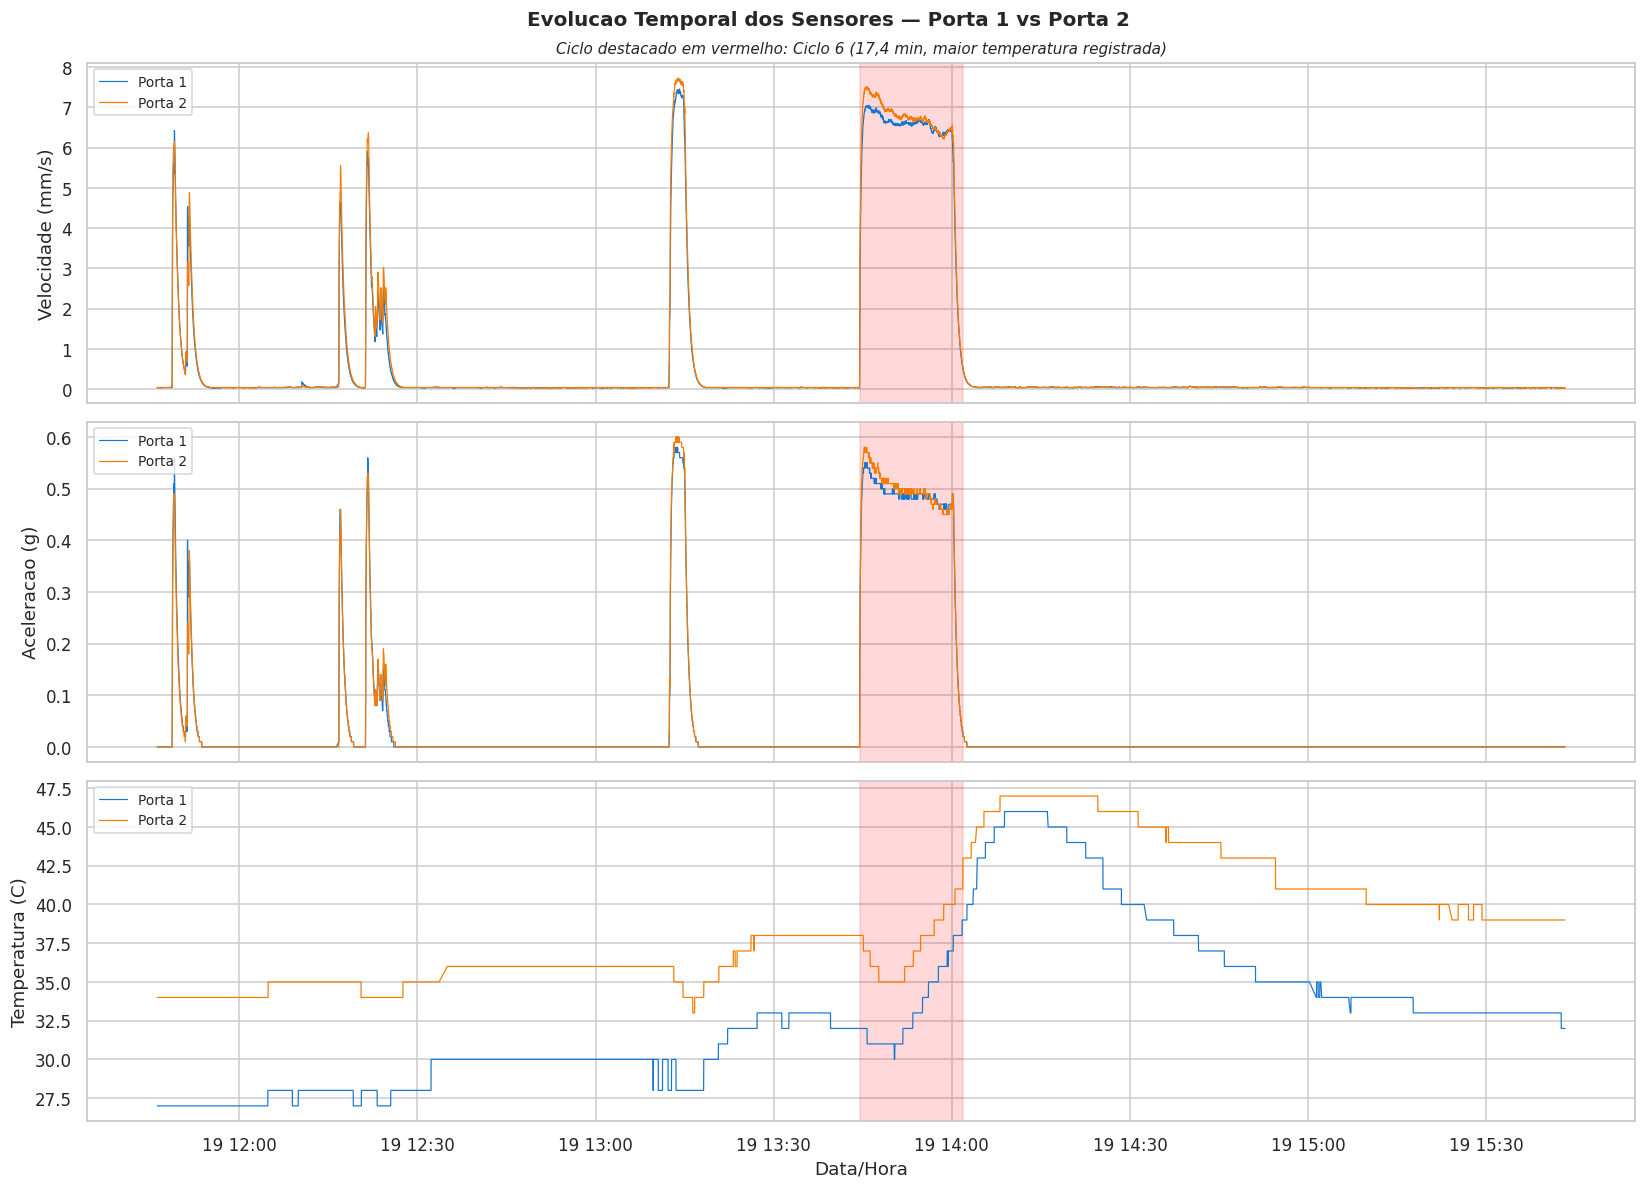

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
pares = [('p1_velocidade', 'p2_velocidade', 'Velocidade (mm/s)'),
         ('p1_aceleracao', 'p2_aceleracao', 'Aceleracao (g)'),
         ('p1_temperatura', 'p2_temperatura', 'Temperatura (C)')]

for ax, (c1, c2, ylabel) in zip(axes, pares):
    ax.plot(df['timestamp'], df[c1], label='Porta 1', color='#1976D2', linewidth=0.8)
    ax.plot(df['timestamp'], df[c2], label='Porta 2', color='#F57C00', linewidth=0.8)
    ax.set_ylabel(ylabel)
    ax.legend(loc='upper left', fontsize=9)

# Destacar o ciclo 6 (mais longo e mais quente) em todos os paineis
c6 = cycles.loc[6]
for ax in axes:
    ax.axvspan(c6['inicio'], c6['fim'], alpha=0.15, color='red')

axes[0].set_title('Ciclo destacado em vermelho: Ciclo 6 (17,4 min, maior temperatura registrada)',
                   fontsize=10, style='italic')
axes[-1].set_xlabel('Data/Hora')
plt.suptitle('Evolucao Temporal dos Sensores — Porta 1 vs Porta 2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_evolucao_temporal.png', bbox_inches='tight')
plt.show()


**Interpretacao:**

- As duas portas seguem trajetorias quase identicas em velocidade e aceleracao,
  confirmando que monitoram o mesmo evento mecanico (provavelmente dois pontos
  de um mesmo eixo ou rolamento).

- A temperatura apresenta um padrao de **acumulo progressivo**: cada ciclo eleva
  a temperatura basal um pouco mais que o anterior, e o resfriamento entre
  ciclos e incompleto quando os ciclos estao proximos no tempo — visivel entre
  os ciclos 1-4 (11h46-12h25), onde a temperatura de repouso sobe gradualmente
  de 27°C para 28-30°C.

- O ciclo 6 (destacado em vermelho) e visualmente distinto dos demais: nao
  apenas dura muito mais tempo, mas tambem sustenta a vibracao em patamar
  elevado por um periodo prolongado, levando a temperatura a um pico muito
  acima do padrao dos ciclos anteriores.


## 6. Correlacao entre Sensores e Pontos de Medicao

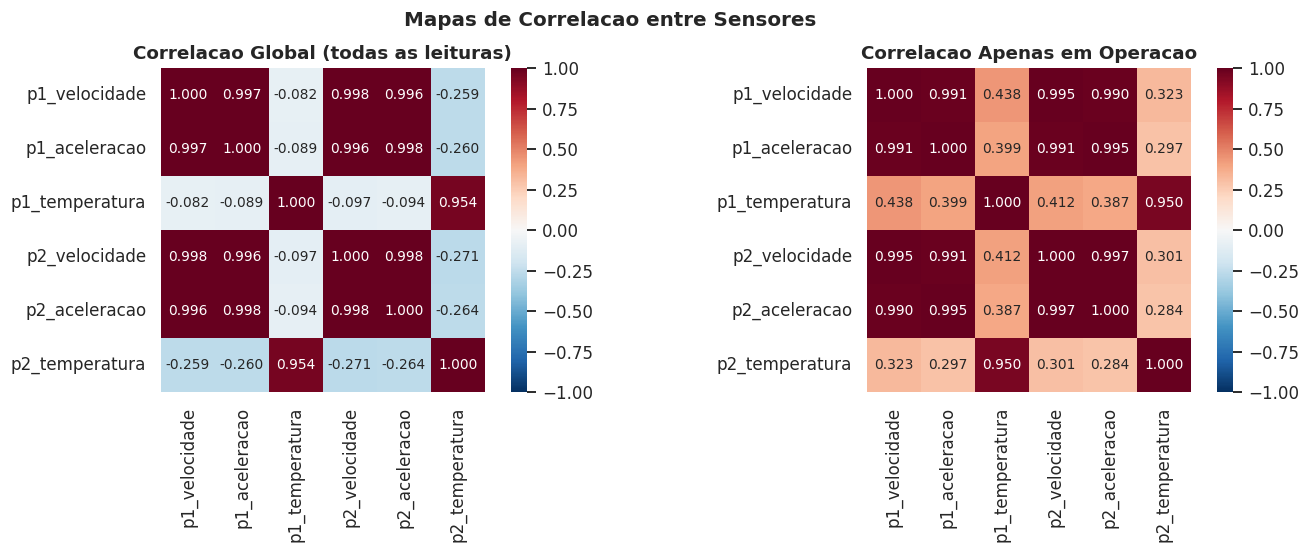

Correlacao P1 x P2 (velocidade): 0.9980
Correlacao P1 x P2 (temperatura): 0.9539
Correlacao velocidade x aceleracao (P1, em operacao): 0.9913


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

corr_all = df[SENSOR_COLS].corr()
sns.heatmap(corr_all, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            ax=axes[0], square=True, vmin=-1, vmax=1, annot_kws={'size': 9})
axes[0].set_title('Correlacao Global (todas as leituras)', fontweight='bold')

corr_run = df[df['running']][SENSOR_COLS].corr()
sns.heatmap(corr_run, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            ax=axes[1], square=True, vmin=-1, vmax=1, annot_kws={'size': 9})
axes[1].set_title('Correlacao Apenas em Operacao', fontweight='bold')

plt.suptitle('Mapas de Correlacao entre Sensores', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_correlacao.png', bbox_inches='tight')
plt.show()

print(f"Correlacao P1 x P2 (velocidade): {df['p1_velocidade'].corr(df['p2_velocidade']):.4f}")
print(f"Correlacao P1 x P2 (temperatura): {df['p1_temperatura'].corr(df['p2_temperatura']):.4f}")
print(f"Correlacao velocidade x aceleracao (P1, em operacao): "
      f"{df[df['running']]['p1_velocidade'].corr(df[df['running']]['p1_aceleracao']):.4f}")


**Interpretacao:**

- A correlacao entre Porta 1 e Porta 2 e muito alta (>0,99 em velocidade,
  ~0,95 em temperatura), confirmando que os dois pontos de medicao respondem
  ao mesmo evento mecanico subjacente. Essa correlacao forte e o proprio
  fundamento do **baseline de consistencia cruzada**: se as duas portas
  divergirem significativamente do padrao historico de correlacao, isso pode
  indicar um defeito assimetrico se desenvolvendo em um dos dois pontos
  (por exemplo, desgaste localizado em apenas um rolamento).

- Velocidade e aceleracao sao fortemente correlacionadas (>0,99) dentro do
  estado de operacao, o que e esperado fisicamente: ambas derivam do mesmo
  sinal de vibracao, mas enfatizam faixas de frequencia diferentes
  (velocidade: desbalanceamento/desalinhamento em baixa frequencia;
  aceleracao: defeitos de rolamento em alta frequencia). Um afastamento entre
  essas duas métricas normalmente correlacionadas seria um sinal de alerta
  para tipo especifico de defeito.


## 7. Deteccao de Outliers

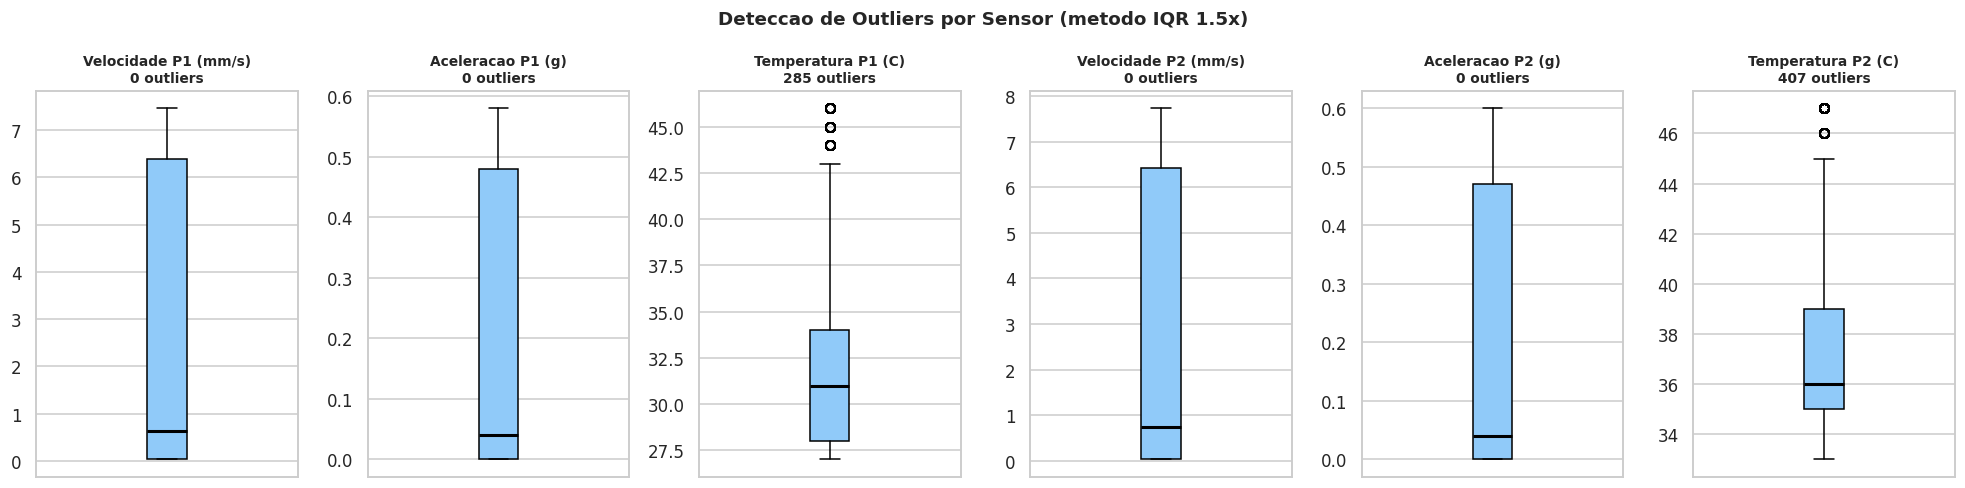

Sensor              Outliers   % total   % em operacao
------------------------------------------------------
p1_velocidade              0     0.00%            nan%
p1_aceleracao              0     0.00%            nan%
p1_temperatura           285     3.97%            0.0%
p2_velocidade              0     0.00%            nan%
p2_aceleracao              0     0.00%            nan%
p2_temperatura           407     5.67%            0.0%


In [8]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4.5))
out_info = {}

for ax, col, lbl in zip(axes, SENSOR_COLS, labels_sensores):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    is_out = (df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)
    n_out = is_out.sum()
    out_info[col] = {'n': n_out, 'pct': n_out/len(df)*100,
                     'pct_running': df[is_out]['running'].mean()*100}
    ax.boxplot(df[col], patch_artist=True,
               boxprops=dict(facecolor='#90CAF9'),
               medianprops=dict(color='black', linewidth=2))
    ax.set_title(f'{lbl}\n{n_out} outliers', fontsize=9, fontweight='bold')
    ax.set_xticks([])

plt.suptitle('Deteccao de Outliers por Sensor (metodo IQR 1.5x)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_outliers.png', bbox_inches='tight')
plt.show()

print(f"{'Sensor':<18} {'Outliers':>9} {'% total':>9} {'% em operacao':>15}")
print("-" * 54)
for col, info in out_info.items():
    print(f"{col:<18} {info['n']:>9,} {info['pct']:>8.2f}% {info['pct_running']:>14.1f}%")


**Interpretacao:** os outliers identificados por IQR correspondem majoritariamente
a leituras durante a operacao — esperado, ja que o proprio ato de ligar o
equipamento produz valores estatisticamente distantes da grande massa de
leituras em repouso (que domina o dataset). Isso confirma que **outliers
estatisticos simples nao equivalem a anomalias operacionais**: a maior parte
desses "outliers" e simplesmente o funcionamento normal do equipamento. Esse
achado motiva a abordagem de baseline **condicionada ao estado operacional**,
desenvolvida na proxima secao.


## 8. Definicao do Baseline Operacional

Com base nos achados da analise exploratoria, o baseline operacional adotado
neste projeto e **condicionado ao estado** (repouso vs operacao) e combina tres
componentes complementares:

1. **Limites estatisticos por estado** (média ± 3 desvios-padrão), calculados
   separadamente para repouso e operação, evitando a mistura de regimes que
   invalidaria um baseline unico.
2. **Baseline de consistência cruzada** entre Porta 1 e Porta 2, monitorando o
   desvio da diferença entre as duas portas em relação ao padrão histórico.
3. **Baseline por ciclo**: estatísticas agregadas de cada ciclo de operação
   (duração, pico de velocidade, pico de temperatura), usadas para comparar
   ciclos entre si e identificar ciclos atípicos.


In [9]:
baseline_stats = {}

for estado, mask in [('idle', ~df['running']), ('running', df['running'])]:
    baseline_stats[estado] = {}
    for col in SENSOR_COLS:
        mu, sigma = df[mask][col].mean(), df[mask][col].std()
        baseline_stats[estado][col] = {
            'media': round(mu, 4),
            'desvio_padrao': round(sigma, 4),
            'limite_inferior_3sigma': round(max(0, mu - 3*sigma), 4),
            'limite_superior_3sigma': round(mu + 3*sigma, 4),
        }

print("=== BASELINE OPERACIONAL — Limites Estatisticos (media +/- 3 sigma) ===\n")
for estado, stats in baseline_stats.items():
    print(f"--- Estado: {estado.upper()} ---")
    for col, s in stats.items():
        print(f"  {col:<18}: media={s['media']:>7.3f}  "
              f"limite=[{s['limite_inferior_3sigma']:>7.3f}, {s['limite_superior_3sigma']:>7.3f}]")
    print()

# Baseline de consistencia cruzada (Porta1 - Porta2)
df['diff_vel']  = df['p1_velocidade'] - df['p2_velocidade']
df['diff_temp'] = df['p1_temperatura'] - df['p2_temperatura']

baseline_stats['cross_port'] = {
    'diff_vel_media': round(df['diff_vel'].mean(), 4),
    'diff_vel_std':   round(df['diff_vel'].std(), 4),
    'diff_temp_media': round(df['diff_temp'].mean(), 4),
    'diff_temp_std':   round(df['diff_temp'].std(), 4),
}
print("--- Baseline de Consistencia Cruzada (Porta1 - Porta2) ---")
print(f"  diff_velocidade : media={baseline_stats['cross_port']['diff_vel_media']:.3f}  "
      f"std={baseline_stats['cross_port']['diff_vel_std']:.3f}")
print(f"  diff_temperatura: media={baseline_stats['cross_port']['diff_temp_media']:.3f}  "
      f"std={baseline_stats['cross_port']['diff_temp_std']:.3f}")


=== BASELINE OPERACIONAL — Limites Estatisticos (media +/- 3 sigma) ===

--- Estado: IDLE ---
  p1_velocidade     : media=  0.073  limite=[  0.000,   0.328]
  p1_aceleracao     : media=  0.001  limite=[  0.000,   0.015]
  p1_temperatura    : media= 33.296  limite=[ 17.370,  49.222]
  p2_velocidade     : media=  0.077  limite=[  0.000,   0.371]
  p2_aceleracao     : media=  0.002  limite=[  0.000,   0.015]
  p2_temperatura    : media= 39.030  limite=[ 26.472,  51.588]

--- Estado: RUNNING ---
  p1_velocidade     : media=  4.672  limite=[  0.000,  11.950]
  p1_aceleracao     : media=  0.352  limite=[  0.000,   0.920]
  p1_temperatura    : media= 30.719  limite=[ 20.486,  40.952]
  p2_velocidade     : media=  4.894  limite=[  0.000,  12.258]
  p2_aceleracao     : media=  0.358  limite=[  0.000,   0.936]
  p2_temperatura    : media= 35.934  limite=[ 29.533,  42.335]

--- Baseline de Consistencia Cruzada (Porta1 - Porta2) ---
  diff_velocidade : media=-0.119  std=0.210
  diff_temperatura: m

In [10]:
# Baseline por ciclo — estatisticas de referencia dos ciclos "tipicos" (excluindo o ciclo 6)
ciclos_tipicos = cycles.drop(index=6)
baseline_ciclo = {
    'duracao_min_media':  round(ciclos_tipicos['duracao_min'].mean(), 2),
    'duracao_min_std':    round(ciclos_tipicos['duracao_min'].std(), 2),
    'vel_max_p1_media':   round(ciclos_tipicos['vel_max_p1'].mean(), 2),
    'temp_max_p1_media':  round(ciclos_tipicos['temp_max_p1'].mean(), 2),
    'temp_max_p2_media':  round(ciclos_tipicos['temp_max_p2'].mean(), 2),
}
baseline_stats['ciclo_tipico'] = baseline_ciclo

print("=== Baseline por Ciclo (referencia: 5 ciclos tipicos, excluindo o ciclo 6) ===")
for k, v in baseline_ciclo.items():
    print(f"  {k:<20}: {v}")

print(f"\nComparacao — Ciclo 6 vs baseline tipico:")
print(f"  Duracao: {cycles.loc[6,'duracao_min']:.1f} min "
      f"(baseline: {baseline_ciclo['duracao_min_media']:.1f} +/- {baseline_ciclo['duracao_min_std']:.1f} min)")
desvio_duracao = (cycles.loc[6,'duracao_min'] - baseline_ciclo['duracao_min_media']) / baseline_ciclo['duracao_min_std']
print(f"  Desvio em unidades de sigma: {desvio_duracao:.1f} sigma")
print(f"  Temperatura maxima P2: {cycles.loc[6,'temp_max_p2']:.0f} C "
      f"(baseline: {baseline_ciclo['temp_max_p2_media']:.1f} C)")


=== Baseline por Ciclo (referencia: 5 ciclos tipicos, excluindo o ciclo 6) ===
  duracao_min_media   : 2.95
  duracao_min_std     : 1.31
  vel_max_p1_media    : 5.8
  temp_max_p1_media   : 28.0
  temp_max_p2_media   : 34.6

Comparacao — Ciclo 6 vs baseline tipico:
  Duracao: 17.4 min (baseline: 3.0 +/- 1.3 min)
  Desvio em unidades de sigma: 11.1 sigma
  Temperatura maxima P2: 43 C (baseline: 34.6 C)


In [11]:
import json

# Persistir o baseline operacional para uso no notebook de treinamento
with open('baseline_operacional.json', 'w') as f:
    json.dump(baseline_stats, f, indent=2, default=str)

print("baseline_operacional.json salvo com sucesso.")
print(json.dumps(baseline_stats, indent=2, default=str))


baseline_operacional.json salvo com sucesso.
{
  "idle": {
    "p1_velocidade": {
      "media": 0.0729,
      "desvio_padrao": 0.0849,
      "limite_inferior_3sigma": 0,
      "limite_superior_3sigma": 0.3276
    },
    "p1_aceleracao": {
      "media": 0.0013,
      "desvio_padrao": 0.0044,
      "limite_inferior_3sigma": 0,
      "limite_superior_3sigma": 0.0145
    },
    "p1_temperatura": {
      "media": 33.2957,
      "desvio_padrao": 5.3087,
      "limite_inferior_3sigma": 17.3697,
      "limite_superior_3sigma": 49.2217
    },
    "p2_velocidade": {
      "media": 0.0768,
      "desvio_padrao": 0.0982,
      "limite_inferior_3sigma": 0,
      "limite_superior_3sigma": 0.3713
    },
    "p2_aceleracao": {
      "media": 0.0015,
      "desvio_padrao": 0.0046,
      "limite_inferior_3sigma": 0,
      "limite_superior_3sigma": 0.0153
    },
    "p2_temperatura": {
      "media": 39.0298,
      "desvio_padrao": 4.186,
      "limite_inferior_3sigma": 26.4717,
      "limite_superior_

## Conclusoes da EDA e do Baseline

| Achado | Implicacao para o Modelo |
|---|---|
| Amostragem irregular (report-on-change) | Features devem incorporar o intervalo de tempo (`dt_seg`) entre leituras |
| Dois estados claros (repouso/operacao) | Baseline e deteccao de anomalias devem ser condicionados ao estado |
| Porta 1 e Porta 2 fortemente correlacionadas | Divergencia entre portas e um sinal de anomalia valioso (feature `diff_vel`, `diff_temp`) |
| Temperatura acumula com inercia termica | Nao pode ser avaliada isoladamente por leitura; picos e taxas de subida importam mais que valores absolutos |
| Outliers simples (IQR) capturam principalmente o estado "operacao" | Justifica abordagem por ML capaz de aprender o padrao multivariado, nao um limiar univariado simples |
| Ciclo 6 destoa fortemente do baseline tipico (>4 sigma em duracao) | Principal candidato a anomalia; sera testado formalmente no proximo notebook |

O baseline operacional definido aqui (limites por estado, consistencia cruzada
entre portas e perfil tipico de ciclo) sera usado tanto como **features de
entrada** para os modelos de Machine Learning quanto como **metodo de
referencia interpretavel** para validar os resultados do Isolation Forest e do
Autoencoder no notebook seguinte.
